In [163]:
#import function used to split the dataset for train and test
from sklearn.model_selection import train_test_split as tts

#import linear regression 
from sklearn.linear_model import LinearRegression 

#import evaluation metrics so we can judge the model afterwards
from sklearn.metrics import mean_squared_error as ms_error, r2_score

#import numpy to calc sqrt mse
import numpy as np

import pandas as pd

import matplotlib.pyplot as plt

In [164]:
dataset = pd.read_csv("data/Aggregated_Configurations.csv")





def extract_site_composition(ions, coefficients, group):

    # Start by giving every element at this site a value of 0
    # If an element is not present in a particular perovskite,
    # its value will stay as 0
    composition = {
        element: 0.0 for element in group
    }

    # If either the ion column or coefficient column is missing,
    # return the default values of 0
    if pd.isna(ions) or pd.isna(coefficients):
        return composition

    # Split the ion string at each semicolon
    # Example:
    # "Cs; FA; MA" becomes ["Cs", "FA", "MA"]
    ion_list = [
        ion.strip()
        for ion in str(ions).split(";")
    ]

    # Split the coefficient string at each semicolon
    # and convert each value into a number
    # Example:
    # "0.05; 0.85; 0.15" becomes [0.05, 0.85, 0.15]
    coefficient_list = [
        float(value.strip())
        for value in str(coefficients).split(";")
    ]

    # Match each ion with the coefficient in the same position
    # Example:
    # Cs -> 0.05
    # FA -> 0.85
    # MA -> 0.15
    for ion, coefficient in zip(ion_list, coefficient_list):

        # Only save species that are expected at this site
        if ion in composition:
            composition[ion] = coefficient

    # Return the finished numerical composition for this site
    return composition





# --------------------------------------------------
# 2. DEFINE THE POSSIBLE SPECIES AT EACH SITE
# --------------------------------------------------

# A-site species
# MA and FA are molecular ions, but they are treated as
# individual composition features in the ML model
a_site_species = [
    "Cs",
    "FA",
    "MA"
]

# B-site species
b_site_species = [
    "Pb",
    "Sn"
]

# X-site species
# Your dataset calls this the "c_ions" column
x_site_species = [
    "Cl",
    "Br",
    "I"
]



# --------------------------------------------------
# 3. EXTRACT THE A-SITE COMPOSITION
# --------------------------------------------------

# Apply the function to every row of the dataset
a_composition = dataset.apply(
    lambda row: extract_site_composition(
        row["Perovskite_composition_a_ions"],
        row["Perovskite_composition_a_ions_coefficients"],
        a_site_species
    ),
    axis=1
)

# Convert the resulting dictionaries into normal DataFrame columns
a_composition = pd.DataFrame(
    a_composition.tolist(),
    index=dataset.index
)



# --------------------------------------------------
# 4. EXTRACT THE B-SITE COMPOSITION
# --------------------------------------------------

b_composition = dataset.apply(
    lambda row: extract_site_composition(
        row["Perovskite_composition_b_ions"],
        row["Perovskite_composition_b_ions_coefficients"],
        b_site_species
    ),
    axis=1
)

# Convert the results into DataFrame columns
b_composition = pd.DataFrame(
    b_composition.tolist(),
    index=dataset.index
)






# --------------------------------------------------
# 5. EXTRACT THE X-SITE COMPOSITION
# --------------------------------------------------

x_composition = dataset.apply(
    lambda row: extract_site_composition(
        row["Perovskite_composition_c_ions"],
        row["Perovskite_composition_c_ions_coefficients"],
        x_site_species
    ),
    axis=1
)

# Convert the results into DataFrame columns
x_composition = pd.DataFrame(
    x_composition.tolist(),
    index=dataset.index
)





# --------------------------------------------------
# 6. COMBINE ALL COMPOSITION FEATURES
# --------------------------------------------------

# Join the A-, B-, and X-site numerical features together
composition_features = pd.concat(
    [
        a_composition,
        b_composition,
        x_composition
    ],
    axis=1
)

# Display the first few rows
display(composition_features.head())



,Cs,FA,MA,Pb,Sn,Cl,Br,I
0,0.005,0.0,0.0,0.995,0.0,0.0,3.0,0.0
1,1.000,0.0,0.0,1.000,0.0,0.0,3.0,0.0
2,1.000,0.0,0.0,1.000,0.0,0.0,3.0,0.0
3,1.000,0.0,0.0,1.000,0.0,0.0,3.0,0.0
4,1.000,0.0,0.0,1.000,0.0,0.0,3.0,0.0


In [165]:
# Add the extracted numerical composition features
# onto the original dataset
dataset = pd.concat(
    [
        dataset,
        composition_features
    ],
    axis=1
)

# Check that the new columns are now present
print(dataset.columns.tolist())

['Perovskite_composition_a_ions', 'Perovskite_composition_a_ions_coefficients', 'Perovskite_composition_b_ions', 'Perovskite_composition_b_ions_coefficients', 'Perovskite_composition_c_ions', 'Perovskite_composition_c_ions_coefficients', 'Cell_architecture', 'Substrate_stack_sequence', 'ETL_stack_sequence', 'HTL_stack_sequence', 'Backcontact_stack_sequence', 'n_records', 'mean_PCE', 'median_PCE', 'std_PCE', 'mean_band_gap', 'median_band_gap', 'std_band_gap', 'mean_Jsc', 'std_Jsc', 'mean_Voc', 'std_Voc', 'mean_FF', 'std_FF', 'Cs', 'FA', 'MA', 'Pb', 'Sn', 'Cl', 'Br', 'I']


In [166]:
#dataset = pd.read_csv("data/Filtered_Experimental_Records.csv")
x = dataset [["Cs",
        "MA",
        "FA",
        "Pb",
        "Sn",
        "Br",
        "I",
        "Cl"]]
y_mean = dataset["mean_band_gap"]
y_median = dataset["median_band_gap"]



In [167]:
#8:2 split for training:test

x_train, x_test, ymean_train, ymean_test = tts(
    x,y_mean,test_size = 0.2, random_state =67)


In [168]:
model1 = LinearRegression()

model1.fit(x_train, ymean_train)

ymean_pred = model1.predict(x_test)



x_train, x_test, ymedian_train, ymedian_test = tts(
    x,y_median,test_size = 0.2, random_state =67)

model2 = LinearRegression()

model2.fit(x_train, ymedian_train)

ymedian_pred = model2.predict(x_test)

In [169]:
#compare with test

mse_mean = ms_error(ymean_test, ymean_pred)
rmse_mean = np.sqrt(mse_mean)
r2_mean = r2_score(ymean_test, ymean_pred)


mse_median = ms_error(ymedian_test, ymedian_pred)
rmse_median = np.sqrt(mse_median)
r2_median = r2_score(ymedian_test, ymedian_pred)

print("RMSE for mean", rmse_mean, "R^2 for mean", r2_mean, "RMSE for median", rmse_median, "R^2 for median", r2_median)



RMSE for mean 0.09863264504272777 R^2 for mean 0.8197479653809365 RMSE for median 0.0993799871761113 R^2 for median 0.8175439429342904


In [170]:
#12000 datatset test



dataset_12000 = pd.read_csv(
    "data/Filtered_Experimental_Records.csv"
)

print("Original external dataset shape:", dataset_12000.shape)



#--------------------------------------------------
#2. EXTRACT A-SITE COMPOSITION
#--------------------------------------------------

#Use the SAME extract_site_composition function that
#was used for the original ~600-entry training dataset
#This converts entries such as:
#Cs; FA; MA
#with coefficients:
#0.05; 0.85; 0.15

#into numerical Cs, FA and MA features

a_composition_12000 = dataset_12000.apply(
    lambda row: extract_site_composition(
        row["Perovskite_composition_a_ions"],
        row["Perovskite_composition_a_ions_coefficients"],
        a_site_species
    ),
    axis=1
)

#Convert the extracted dictionaries into DataFrame columns
a_composition_12000 = pd.DataFrame(
    a_composition_12000.tolist(),
    index=dataset_12000.index
)


#b site 

#Extract Pb and Sn coefficients from the B-site
b_composition_12000 = dataset_12000.apply(
    lambda row: extract_site_composition(
        row["Perovskite_composition_b_ions"],
        row["Perovskite_composition_b_ions_coefficients"],
        b_site_species
    ),
    axis=1
)

#Convert the extracted dictionaries into DataFrame columns
b_composition_12000 = pd.DataFrame(
    b_composition_12000.tolist(),
    index=dataset_12000.index
)



#x site

#Extract Cl, Br and I coefficients
#Your dataset calls the X-site "c_ions"
x_composition_12000 = dataset_12000.apply(
    lambda row: extract_site_composition(
        row["Perovskite_composition_c_ions"],
        row["Perovskite_composition_c_ions_coefficients"],
        x_site_species
    ),
    axis=1
)

#Convert the extracted dictionaries into DataFrame columns
x_composition_12000 = pd.DataFrame(
    x_composition_12000.tolist(),
    index=dataset_12000.index
)




#5. COMBINE ALL COMPOSITION FEATURES


#Join the A-, B-, and X-site numerical features together
composition_features_12000 = pd.concat(
    [
        a_composition_12000,
        b_composition_12000,
        x_composition_12000
    ],
    axis=1
)

#Add the numerical composition features onto
#the external dataset
dataset_12000 = pd.concat(
    [
        dataset_12000,
        composition_features_12000
    ],
    axis=1
)




#6. DEFINE THE INPUT FEATURES



feature_columns = [
    "Cs",
    "MA",
    "FA",
    "Pb",
    "Sn",
    "Br",
    "I",
    "Cl"
]




#7. REMOVE ROWS THAT CANNOT BE TESTED

#Remove rows where:
#- one of the eight composition features is missing
#- the external band-gap value is missing

#Perovskite_Band_Gap is the actual band-gap value
#that the two models will be tested against
external_test = dataset_12000.dropna(
    subset=feature_columns + ["Perovskite_band_gap"]
).copy()

#Display how many rows remain after cleaning
print(
    "Entries available for external testing:",
    len(external_test)
)




#8. DEFINE X AND y FOR THE EXTERNAL TEST


#X contains the same eight composition features
#used during original model training
x_12000 = external_test[
    feature_columns
]

#y contains the ACTUAL band gaps reported
#in the 12,000-entry dataset
y_12000 = external_test[
    "Perovskite_band_gap"
]




#9. USE MODEL 1 TO PREDICT THE 12,000 DATASET


#model1 was trained on MEAN band gap

#Do NOT call model1.fit() again here.
#We want to test the already-trained model.
pred_12000_mean = model1.predict(
    x_12000
)



#model2 predict


pred_12000_median = model2.predict(
    x_12000
)


#model1 predict


mse_12000_mean = ms_error(
    y_12000,
    pred_12000_mean
)


rmse_12000_mean = np.sqrt(
    mse_12000_mean
)


r2_12000_mean = r2_score(
    y_12000,
    pred_12000_mean
)




mse_12000_median = ms_error(
    y_12000,
    pred_12000_median
)


rmse_12000_median = np.sqrt(
    mse_12000_median
)


r2_12000_median = r2_score(
    y_12000,
    pred_12000_median
)


external_results = pd.DataFrame({
    "Model trained using": [
        "Mean band gap",
        "Median band gap"
    ],
    
    "External RMSE": [
        rmse_12000_mean,
        rmse_12000_median
    ],
    
    "External R²": [
        r2_12000_mean,
        r2_12000_median
    ]
})


display(external_results)




prediction_comparison = pd.DataFrame({
    "Actual band gap": y_12000.to_numpy(),
    "Prediction - mean model": pred_12000_mean,
    "Prediction - median model": pred_12000_median
})

display(
    prediction_comparison.head()
)

Original external dataset shape: (12708, 20)
Entries available for external testing: 12708


,Model trained using,External RMSE,External R²
0,Mean band gap,0.184784,-1.919667
1,Median band gap,0.186117,-1.961927


,Actual band gap,Prediction - mean model,Prediction - median model
0,1.27,1.299532,1.299797
1,1.75,1.976482,1.976123
2,1.27,1.299532,1.299797
3,1.37,1.525182,1.525239
4,1.65,1.750832,1.750681


In [171]:
#train and test on 12000

x_tt12000 = external_test[feature_columns]
y_tt12000 = external_test["Perovskite_band_gap"]
(x_tt12000_train, x_tt12000_test, y_tt12000_train, 
 y_tt12000_test)  = tts(x_tt12000, 
                        y_tt12000, test_size=0.2, random_state=67)

model_12000 = LinearRegression()
model_12000.fit(x_tt12000_train, y_tt12000_train)

y_tt12000_pred = model_12000.predict(x_tt12000_test)

mse_tt12000 =ms_error(y_tt12000_test, y_tt12000_pred)
rmse_tt12000 = np.sqrt(mse_tt12000)
r2_tt12000 = r2_score(y_tt12000_test, y_tt12000_pred)

print("12000 train test rmse:", rmse_tt12000, "12000 train test r^2:", r2_tt12000)


12000 train test rmse: 0.050151763751754556 12000 train test r^2: 0.7757770984990997


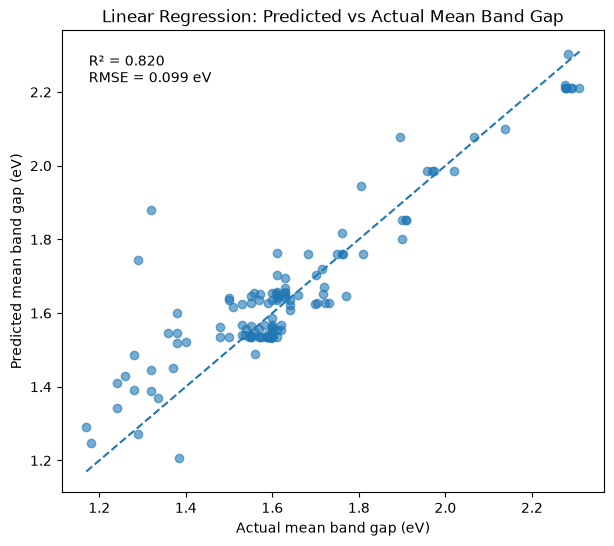

In [172]:


# Create a new figure
plt.figure(figsize=(7, 6))

# Plot actual band gap on the x-axis
# and predicted band gap on the y-axis
plt.scatter(
    ymean_test,
    ymean_pred,
    alpha=0.6
)

# Find the overall minimum value
# so the perfect-prediction line spans the full graph
minimum = min(
    ymean_test.min(),
    ymean_pred.min()
)

# Find the overall maximum value
maximum = max(
    ymean_test.max(),
    ymean_pred.max()
)

# Plot the y = x perfect-prediction line
plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

# Label the axes
plt.xlabel("Actual mean band gap (eV)")
plt.ylabel("Predicted mean band gap (eV)")

# Add the graph title
plt.title(
    "Linear Regression: Predicted vs Actual Mean Band Gap"
)

# Display the R² and RMSE values on the graph
plt.text(
    0.05,
    0.95,
    f"R² = {r2_mean:.3f}\nRMSE = {rmse_mean:.3f} eV",
    transform=plt.gca().transAxes,
    verticalalignment="top"
)

# Display the graph
plt.show()